# **Data Preparation & Metrics**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

github_csv_url = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
print(f"Downloading IMDB dataset from: {github_csv_url}")
df = pd.read_csv(github_csv_url)

df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})

df = df.sample(10000, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    df['review'].values, df['sentiment'].values, test_size=0.2, random_state=42
)

def evaluate_and_plot(model_name, y_true, y_pred):
    print(f"====== {model_name} ======")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
    print(f"F1 Score:  {f1_score(y_true, y_pred):.4f}\n")

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# **1. Logistic Regression**

====== Logistic Regression ======
Precision: 0.8519
Recall:    0.9021
F1 Score:  0.8763



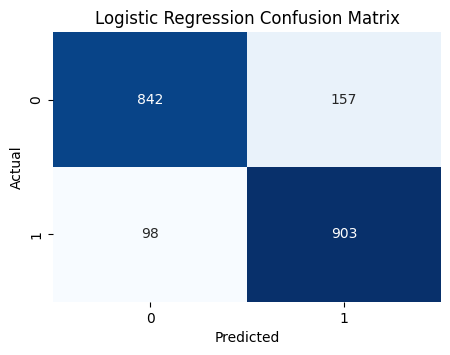

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

lr_preds = lr_model.predict(X_test_tfidf)
evaluate_and_plot("Logistic Regression", y_test, lr_preds)

# **2. LSTM Model (TensorFlow/Keras)**

Epoch 1/4


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


113/113 ━━━━━━━━━━━━━━━━━━━━ 48s 346ms/step - accuracy: 0.5114 - loss: 0.6930 - val_accuracy: 0.5200 - val_loss: 0.6907
Epoch 2/4
113/113 ━━━━━━━━━━━━━━━━━━━━ 39s 335ms/step - accuracy: 0.5715 - loss: 0.6773 - val_accuracy: 0.5575 - val_loss: 0.6689
Epoch 3/4
113/113 ━━━━━━━━━━━━━━━━━━━━ 38s 312ms/step - accuracy: 0.6242 - loss: 0.6093 - val_accuracy: 0.5612 - val_loss: 0.6894
Epoch 4/4
113/113 ━━━━━━━━━━━━━━━━━━━━ 37s 322ms/step - accuracy: 0.6803 - loss: 0.5133 - val_accuracy: 0.5650 - val_loss: 0.7586
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step
====== LSTM ======
Precision: 0.6569
Recall:    0.2907
F1 Score:  0.4030



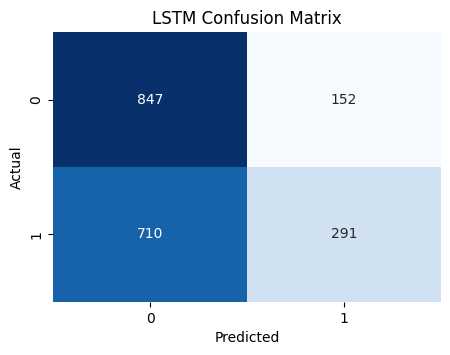

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

vocab_size = 10000
max_length = 200

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=max_length, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=max_length, padding='post', truncating='post')

lstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, input_length=max_length),
    LSTM(64, return_sequences=False, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

lstm_model.fit(X_train_seq, y_train, epochs=4, batch_size=64, validation_split=0.1, verbose=1)

lstm_probs = lstm_model.predict(X_test_seq)
lstm_preds = (lstm_probs > 0.5).astype(int).flatten()
evaluate_and_plot("LSTM", y_test, lstm_preds)

# **3. Vanilla Transformer (Custom Keras Layers)**

Epoch 1/3
113/113 ━━━━━━━━━━━━━━━━━━━━ 99s 838ms/step - accuracy: 0.6251 - loss: 0.6379 - val_accuracy: 0.7713 - val_loss: 0.4764
Epoch 2/3
113/113 ━━━━━━━━━━━━━━━━━━━━ 89s 786ms/step - accuracy: 0.8550 - loss: 0.3377 - val_accuracy: 0.8450 - val_loss: 0.3784
Epoch 3/3
113/113 ━━━━━━━━━━━━━━━━━━━━ 106s 473ms/step - accuracy: 0.9361 - loss: 0.1701 - val_accuracy: 0.8363 - val_loss: 0.4681
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step
====== Vanilla Transformer ======
Precision: 0.8399
Recall:    0.8701
F1 Score:  0.8548



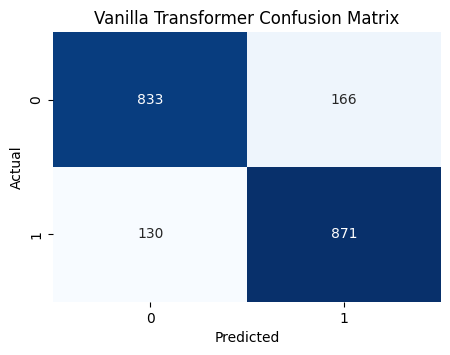

In [6]:
from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization, GlobalAveragePooling1D, Input
from tensorflow.keras.models import Model

class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = Sequential([Dense(ff_dim, activation="relu"), Dense(embed_dim)])
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(rate)
        self.dropout2 = Dropout(rate)

    def call(self, inputs, training=None):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

class TokenAndPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim):
        super().__init__()
        self.token_emb = Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)
        x = self.token_emb(x)
        return x + positions

embed_dim = 64
num_heads = 2
ff_dim = 64

inputs = Input(shape=(max_length,))
embedding_layer = TokenAndPositionEmbedding(max_length, vocab_size, embed_dim)
x = embedding_layer(inputs)
transformer_block = TransformerBlock(embed_dim, num_heads, ff_dim)
x = transformer_block(x)
x = GlobalAveragePooling1D()(x)
x = Dropout(0.2)(x)
x = Dense(32, activation="relu")(x)
outputs = Dense(1, activation="sigmoid")(x)

transformer_model = Model(inputs=inputs, outputs=outputs)
transformer_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

transformer_model.fit(X_train_seq, y_train, batch_size=64, epochs=3, validation_split=0.1)

trans_probs = transformer_model.predict(X_test_seq)
trans_preds = (trans_probs > 0.5).astype(int).flatten()
evaluate_and_plot("Vanilla Transformer", y_test, trans_preds)

# **4. Pretrained BERT (Hugging Face)**

Loading Pretrained BERT pipeline...


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Running inference on 100 reviews...


  0%|          | 0/100 [00:00<?, ?it/s]

====== Pretrained BERT ======
Precision: 0.9333
Recall:    0.8750
F1 Score:  0.9032



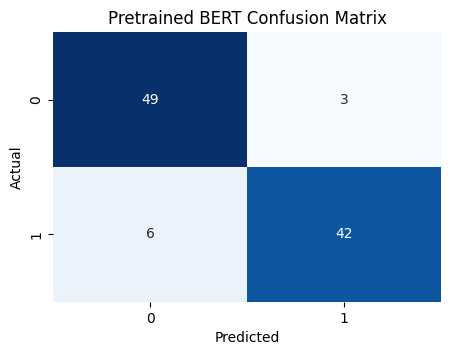

In [8]:
from transformers import pipeline
from tqdm.auto import tqdm

print("Loading Pretrained BERT pipeline...")
bert_classifier = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    truncation=True,
    max_length=512
)


test_reviews = X_test[:100].tolist()
y_test_subset = y_test[:100]

print(f"Running inference on {len(test_reviews)} reviews...")

bert_results = []
for review in tqdm(test_reviews):
    result = bert_classifier(review)
    bert_results.append(result[0])

bert_preds = [1 if res['label'] == 'POSITIVE' else 0 for res in bert_results]

evaluate_and_plot("Pretrained BERT", y_test_subset, bert_preds)